# Lab 14-03 · Assembly and the Compilation Stack

Companion to [chapter 14-03](../../chapters/14-03-assembly-and-the-compilation-stack.md). Four parts: compiler output at two optimization levels; object files, relocations and linking; running programs on an RV32I simulator; and structure layouts under different ABIs. You need `clang`, `ld.lld` and the LLVM tools (see the [lab handout](README.md)). Run the cells in order.

In [1]:
import re, subprocess, sys, tempfile
from pathlib import Path
sys.path.insert(0, str(Path('../../verify').resolve()))
from _rv32 import tool, build, run_function, Sim, START    # the course's RV32I toolkit

CLANG, MC, LLD, OBJDUMP = tool('clang'), tool('llvm-mc'), tool('ld.lld'), tool('llvm-objdump')
RV32 = ['--target=riscv32', '-march=rv32i', '-mabi=ilp32', '-ffreestanding', '-nostdlib', '-fno-builtin']
print(subprocess.run([CLANG, '--version'], capture_output=True, text=True).stdout.splitlines()[0])

def sh(*args):
    out = subprocess.run(list(args), capture_output=True, text=True, check=True).stdout
    return out

def asm_of(cfile, opt):
    out = sh(CLANG, *RV32, opt, '-S', cfile, '-o', '-')
    keep = [ln for ln in out.splitlines() if ln.strip() and not re.match(r'\s*\.(file|attribute|ident|section|addrsig|p2align|type|size|option)', ln)
            and not ln.lstrip().startswith('#') and not ln.startswith('.Lfunc_end')]
    return '\n'.join(keep)

Ubuntu clang version 18.1.3 (1ubuntu1)


## Part 1 · What the compiler writes

Compile the increment loop at `-O0` and `-O2`.

**Predict first:** how many stack loads (`lw ... (sp)`, or `(s0)` when the compiler uses a frame pointer) will the `-O0` loop contain? Will the `-O2` loop look like the index version or the pointer version of Example 14-03.2?

In [2]:
for opt in ('-O0', '-O2'):
    text = asm_of('inc.c', opt)
    print(f'===== inc.c at {opt}: {len([l for l in text.splitlines() if l.startswith(chr(9)) and not l.lstrip().startswith(".")])} instructions in the listing')
    print(text, '\n')

===== inc.c at -O0: 31 instructions in the listing
	.text
	.globl	inc                             # -- Begin function inc
inc:                                    # @inc
	addi	sp, sp, -32
	sw	ra, 28(sp)                      # 4-byte Folded Spill
	sw	s0, 24(sp)                      # 4-byte Folded Spill
	addi	s0, sp, 32
	sw	a0, -12(s0)
	sw	a1, -16(s0)
	sw	a2, -20(s0)
	li	a0, 0
	sw	a0, -24(s0)
	j	.LBB0_1
.LBB0_1:                                # =>This Inner Loop Header: Depth=1
	lw	a0, -24(s0)
	lw	a1, -16(s0)
	bge	a0, a1, .LBB0_4
	j	.LBB0_2
.LBB0_2:                                #   in Loop: Header=BB0_1 Depth=1
	lw	a2, -20(s0)
	lw	a0, -12(s0)
	lw	a1, -24(s0)
	slli	a1, a1, 2
	add	a1, a0, a1
	lw	a0, 0(a1)
	add	a0, a0, a2
	sw	a0, 0(a1)
	j	.LBB0_3
.LBB0_3:                                #   in Loop: Header=BB0_1 Depth=1
	lw	a0, -24(s0)
	addi	a0, a0, 1
	sw	a0, -24(s0)
	j	.LBB0_1
.LBB0_4:
	lw	ra, 28(sp)                      # 4-byte Folded Reload
	lw	s0, 24(sp)                      # 4-byte 

In [3]:
data = {0x20000 + i: 0 for i in range(400)}
for opt in ('-O0', '-O1', '-O2'):
    r = run_function({'inc.c': Path('inc.c').read_text()}, 'inc', [0x20000, 100, 3], opt=opt, data=data)
    print(f'{opt}: {r["count"]:5d} instructions for 100 elements, {r["text"]} bytes of code in the program')

-O0:  1718 instructions for 100 elements, 152 bytes of code in the program


-O1:   504 instructions for 100 elements, 60 bytes of code in the program
-O2:   504 instructions for 100 elements, 60 bytes of code in the program


## Part 2 · Object files and linking

Assemble `main.s` and `fib.s` separately and look inside the object files: the symbol table and the relocations the linker must apply. Then link twice, with and without relaxation.

In [4]:
td = Path(tempfile.mkdtemp())
for f in ('main.s', 'fib.s'):
    sh(MC, '-triple=riscv32', '-mattr=-c,+relax', '-filetype=obj', f, '-o', str(td / (f + '.o')))
    print(f'===== {f}.o: symbols'); print(sh(OBJDUMP, '-t', str(td / (f + '.o'))).split('SYMBOL TABLE:')[1].strip())
    print(f'----- relocations'); print(sh(OBJDUMP, '-r', str(td / (f + '.o'))).split('RELOCATION RECORDS')[1].strip(), '\n')

===== main.s.o: symbols


00000000 l       .text	00000000 $x.0
00000000 g       .text	00000000 _start
00000000         *UND*	00000000 fib
----- relocations
FOR [.text]:
OFFSET   TYPE                     VALUE
00000004 R_RISCV_CALL_PLT         fib
00000004 R_RISCV_RELAX            *ABS* 

===== fib.s.o: symbols
00000000 l       .text	00000000 $x.0
0000004c l       .text	00000000 base
00000000 g       .text	00000000 fib
----- relocations
FOR [.text]:
OFFSET   TYPE                     VALUE
00000004 R_RISCV_BRANCH           base
00000020 R_RISCV_CALL_PLT         fib
00000020 R_RISCV_RELAX            *ABS*
00000030 R_RISCV_CALL_PLT         fib
00000030 R_RISCV_RELAX            *ABS* 



In [5]:
for relax in (False, True):
    elf = td / f'prog_{relax}.elf'
    sh(LLD, '-m', 'elf32lriscv', '-Ttext=0x10000', '-e', '_start', *([] if relax else ['--no-relax']),
       str(td / 'main.s.o'), str(td / 'fib.s.o'), '-o', str(elf))
    dis = sh(OBJDUMP, '-d', '--no-show-raw-insn', str(elf))
    calls = [ln.strip() for ln in dis.splitlines() if re.search(r'\b(auipc|jalr|jal)\b', ln) and 'ret' not in ln]
    size = int(re.search(r'\.text\s+(\d+)', sh(tool('llvm-size'), '-A', str(elf))).group(1))
    print(f'relaxation {"on " if relax else "off"}: {size} bytes of code; call sites:')
    for c in calls: print('    ', c)

relaxation off: 96 bytes of code; call sites:
     10004:      	auipc	ra, 0x0
     10008:      	jalr	0xc(ra) <fib>
     10030:      	auipc	ra, 0x0
     10034:      	jalr	-0x20(ra) <fib>
     10040:      	auipc	ra, 0x0
     10044:      	jalr	-0x30(ra) <fib>
relaxation on : 84 bytes of code; call sites:
     10004:      	jal	0x1000c <fib>
     1002c:      	jal	0x1000c <fib>
     10038:      	jal	0x1000c <fib>


## Part 3 · Running it

`run_function` links a start-up stub that loads the arguments and calls the function, runs everything on the simulator, and reports the result, the instructions executed inside the function, the calls and the stack depth.

**Predict first:** for the hand-written `fib(15)`, use $21F(n+1) - 18$ and $16(n-1)$.

In [6]:
rows = [('fib.s (hand-written)', {'fib.s': Path('fib.s').read_text()}, '-O2'),
        ('fib.c at -O0', {'fib.c': Path('fib.c').read_text()}, '-O0'),
        ('fib.c at -O2', {'fib.c': Path('fib.c').read_text()}, '-O2')]
for name, srcs, opt in rows:
    r = run_function(srcs, 'fib', [15], opt=opt)
    print(f'{name:22s} fib(15) = {r["value"]}: {r["count"]:6d} instructions, {r["calls"]["fib"]:5d} calls, stack {r["depth"]} bytes')

fib.s (hand-written)   fib(15) = 610:  20709 instructions,  1973 calls, stack 224 bytes


fib.c at -O0           fib(15) = 610:  42415 instructions,  1973 calls, stack 480 bytes


fib.c at -O2           fib(15) = 610:  22317 instructions,   987 calls, stack 240 bytes


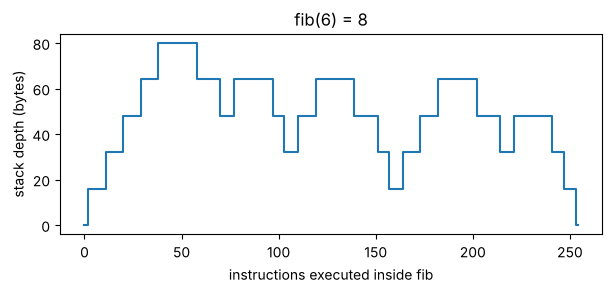

In [7]:
import matplotlib.pyplot as plt
mem, syms, entry, _ = build({'start.s': START.format(body='    li   a0, 6\n    call fib'), 'fib.s': Path('fib.s').read_text()})
sim, trace = Sim(mem, entry), []
sim.run(trace=trace)
start = next(i for i, (pc, _) in enumerate(trace) if pc == syms['fib'])
depth = [0x80000 - sp for _, sp in trace[start:]]
plt.figure(figsize=(7, 2.6)); plt.step(range(len(depth)), depth, where='post')
plt.xlabel('instructions executed inside fib'); plt.ylabel('stack depth (bytes)'); plt.title(f'fib(6) = {sim.x[10]}'); plt.show()

## Part 4 · Structure layouts under three ABIs

Compile `layouts.c` for 32-bit RISC-V (ILP32), 64-bit RISC-V (LP64) and x86-64 (LP64), and read the array of sizes and offsets the compiler computed.

In [8]:
names = ['sizeof A', 'offset A.i', 'offset A.s', 'offset A.d', 'sizeof A reordered', 'sizeof P']
targets = {'RV32 (ILP32)': ['--target=riscv32', '-march=rv32i', '-mabi=ilp32'],
           'RV64 (LP64)': ['--target=riscv64', '-march=rv64i', '-mabi=lp64'],
           'x86-64 (LP64)': ['--target=x86_64-linux-gnu']}
for t, flags in targets.items():
    out = sh(CLANG, *flags, '-ffreestanding', '-O0', '-S', 'layouts.c', '-o', '-')
    vals = [int(x) for x in re.findall(r'^\s*\.(?:word|long)\s+(-?\d+)', out[out.index('layout:'):], re.M)][:len(names)]
    print(f'{t:14s}', dict(zip(names, vals)))

RV32 (ILP32)   {'sizeof A': 24, 'offset A.i': 4, 'offset A.s': 8, 'offset A.d': 16, 'sizeof A reordered': 16, 'sizeof P': 8}
RV64 (LP64)    {'sizeof A': 24, 'offset A.i': 4, 'offset A.s': 8, 'offset A.d': 16, 'sizeof A reordered': 16, 'sizeof P': 16}
x86-64 (LP64)  {'sizeof A': 24, 'offset A.i': 4, 'offset A.s': 8, 'offset A.d': 16, 'sizeof A reordered': 16, 'sizeof P': 16}


**Explore.** Add `long long` and pointer members to the structures and predict their offsets on each target before compiling. Then reorder `struct A`'s members in every possible order (there are 24) and find which orders reach the minimum size.